In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import ndimage as ndi
from skimage.morphology import skeletonize

IMAGE_PATH = Path("VCC7_full.png")
OUTPUT_DIR = Path("results_v2")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.rcParams["figure.figsize"] = (12, 12)

print("환경 설정 완료")

환경 설정 완료


이미지 크기: 2400 x 2400


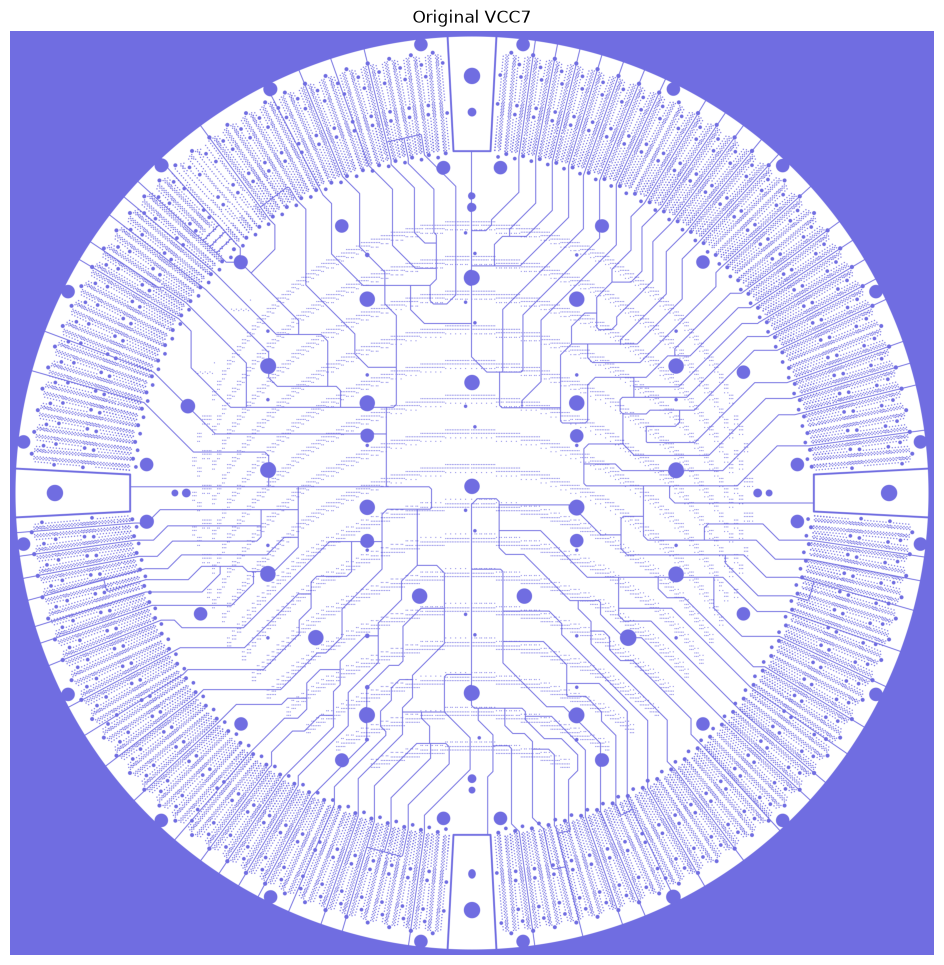

In [2]:
img_bgr = cv2.imread(str(IMAGE_PATH))

if img_bgr is None:
    raise FileNotFoundError(
        f"파일을 찾을 수 없습니다: {IMAGE_PATH.resolve()}"
    )

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

height, width = img_rgb.shape[:2]

print(f"이미지 크기: {width} x {height}")

plt.imshow(img_rgb)
plt.title("Original VCC7")
plt.axis("off")
plt.show()

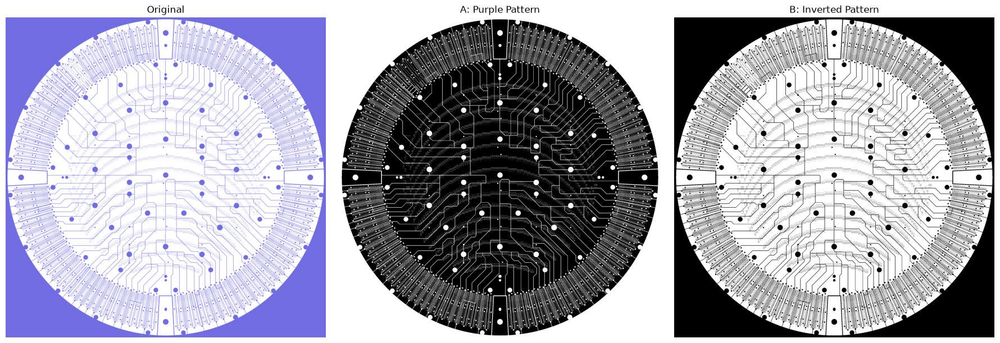

In [3]:
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

lower = np.array([105, 40, 40])
upper = np.array([145, 255, 255])

purple_mask = cv2.inRange(hsv, lower, upper) > 0

# 보라색 영역과 반대 영역
mask_a = purple_mask
mask_b = ~purple_mask

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Original")

axes[1].imshow(mask_a, cmap="gray")
axes[1].set_title("A: Purple Pattern")

axes[2].imshow(mask_b, cmap="gray")
axes[2].set_title("B: Inverted Pattern")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# 실제 구리 영역 확인 후 수정
copper = mask_a.copy()

print("분석 대상 픽셀:", np.sum(copper))

분석 대상 픽셀: 2085009


연결 성분 수: 33514
면적 상위 10개:
[1612493    1435    1435    1434    1434    1280    1279    1279    1279
    1279]


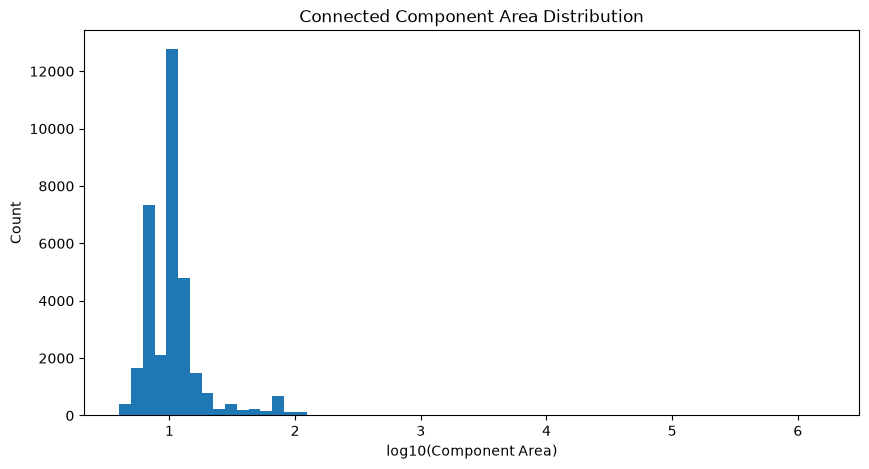

In [5]:
num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        copper.astype(np.uint8),
        connectivity=8
    )
)

areas = stats[1:, cv2.CC_STAT_AREA]

print("연결 성분 수:", num_labels - 1)

print("면적 상위 10개:")
print(np.sort(areas)[-10:][::-1])

plt.figure(figsize=(10, 5))
plt.hist(
    np.log10(areas[areas > 0]),
    bins=60
)

plt.xlabel("log10(Component Area)")
plt.ylabel("Count")
plt.title("Connected Component Area Distribution")
plt.show()

남은 연결 영역: 202


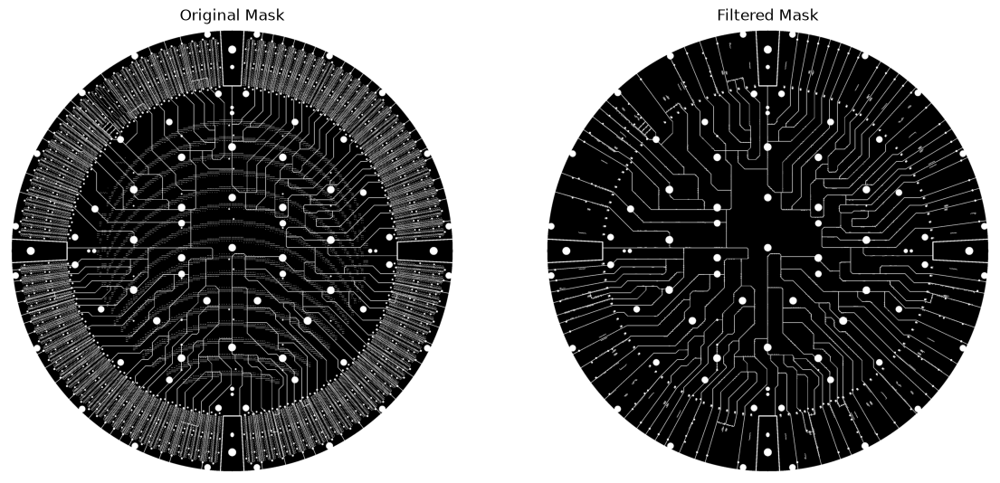

In [6]:
MIN_COMPONENT_AREA = 100

valid_ids = np.where(
    stats[:, cv2.CC_STAT_AREA] >= MIN_COMPONENT_AREA
)[0]

# 배경 제외
valid_ids = valid_ids[valid_ids != 0]

filtered_mask = np.isin(labels, valid_ids)

print("남은 연결 영역:", len(valid_ids))

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(copper, cmap="gray")
axes[0].set_title("Original Mask")

axes[1].imshow(filtered_mask, cmap="gray")
axes[1].set_title("Filtered Mask")

for ax in axes:
    ax.axis("off")

plt.show()

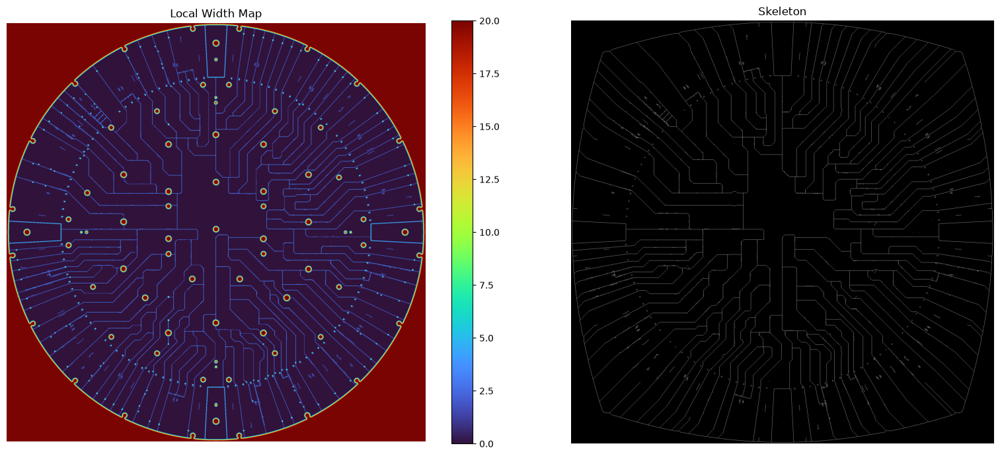

Skeleton pixels: 85027


In [7]:
mask_uint8 = filtered_mask.astype(np.uint8)

dist = cv2.distanceTransform(
    mask_uint8,
    cv2.DIST_L2,
    5
)

local_width = 2 * dist

skeleton = skeletonize(filtered_mask)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

im = axes[0].imshow(
    local_width,
    cmap="turbo",
    vmin=0,
    vmax=20
)

axes[0].set_title("Local Width Map")
plt.colorbar(im, ax=axes[0])

axes[1].imshow(skeleton, cmap="gray")
axes[1].set_title("Skeleton")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Skeleton pixels:", np.sum(skeleton))

,label,area,x,y
0,1,1612493,1200.003723,1202.592195
1,164,1435,1199.493380,116.137282
2,16619,1435,116.137282,1199.493380
3,33028,1434,1199.500000,2282.849372
4,16636,1434,2282.849372,1199.500000
5,21957,1280,793.868750,1575.282813
6,16536,1279,1199.490227,1182.229867
7,12287,1279,1199.487099,912.565285
8,13125,1279,1471.525410,965.608288
9,16902,1279,927.474590,1236.608288


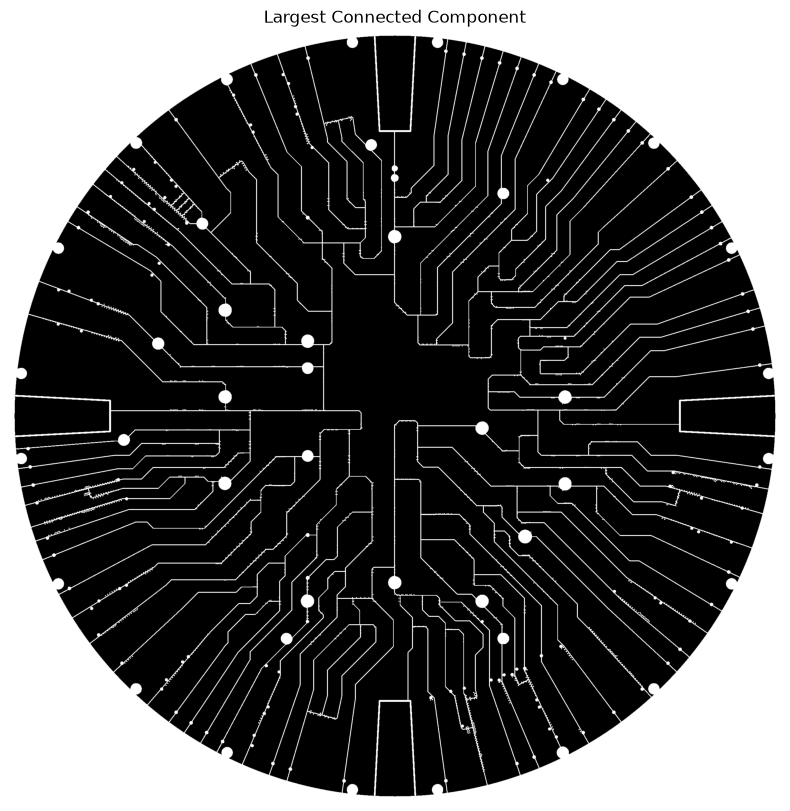

In [8]:
# 가장 큰 연결 성분 10개 확인
component_df = pd.DataFrame({
    "label": np.arange(1, num_labels),
    "area": stats[1:, cv2.CC_STAT_AREA],
    "x": centroids[1:, 0],
    "y": centroids[1:, 1]
})

component_df = component_df.sort_values(
    "area", ascending=False
).reset_index(drop=True)

display(component_df.head(10))

# 가장 큰 연결 성분 시각화
largest_id = int(component_df.iloc[0]["label"])
largest_mask = labels == largest_id

plt.figure(figsize=(10, 10))
plt.imshow(largest_mask, cmap="gray")
plt.title("Largest Connected Component")
plt.axis("off")
plt.show()

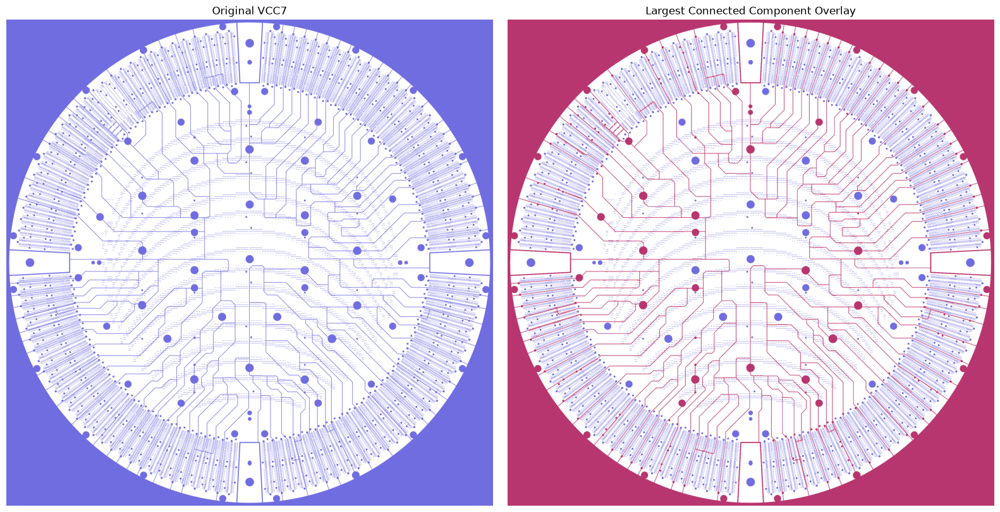

In [9]:
# Cell 8 - 가장 큰 연결 성분을 원본에 표시

overlay = img_rgb.copy()

# 가장 큰 연결 성분을 빨간색으로 표시
overlay[largest_mask] = [255, 0, 0]

# 원본과 50% 혼합
result = cv2.addWeighted(
    img_rgb, 0.5,
    overlay, 0.5,
    0
)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(img_rgb)
axes[0].set_title("Original VCC7")

axes[1].imshow(result)
axes[1].set_title("Largest Connected Component Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

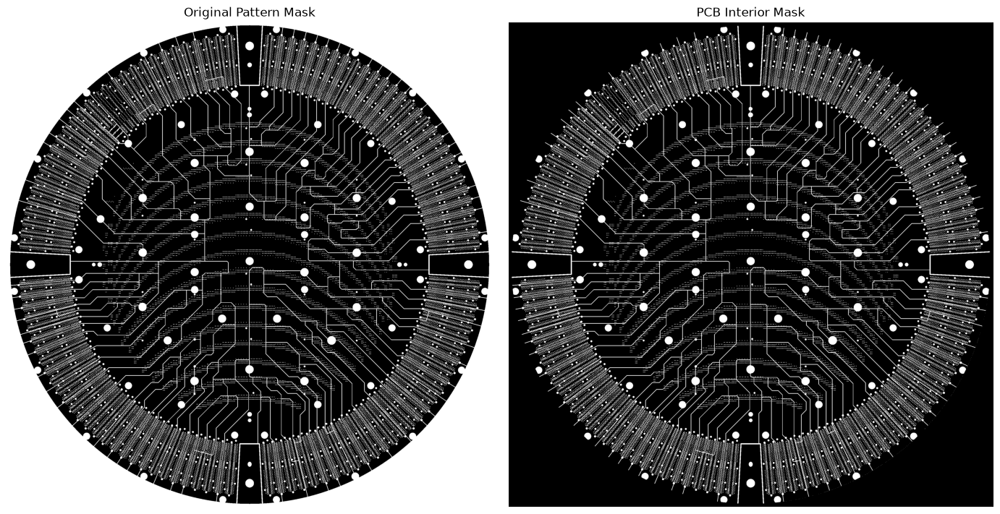

In [10]:
# PCB 중심과 반지름 (초기 추정값)
cx = width // 2
cy = height // 2

radius = min(width, height) // 2 - 15

Y, X = np.ogrid[:height, :width]

pcb_mask = (
    (X - cx)**2 + (Y - cy)**2 <= radius**2
)

# 원형 PCB 내부의 보라색 패턴만 유지
pcb_copper = copper & pcb_mask

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(copper, cmap="gray")
axes[0].set_title("Original Pattern Mask")

axes[1].imshow(pcb_copper, cmap="gray")
axes[1].set_title("PCB Interior Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

PCB 내부 연결 성분 수: 33692
상위 10개 면적:
[252233   1435   1435   1434   1434   1280   1279   1279   1279   1279]


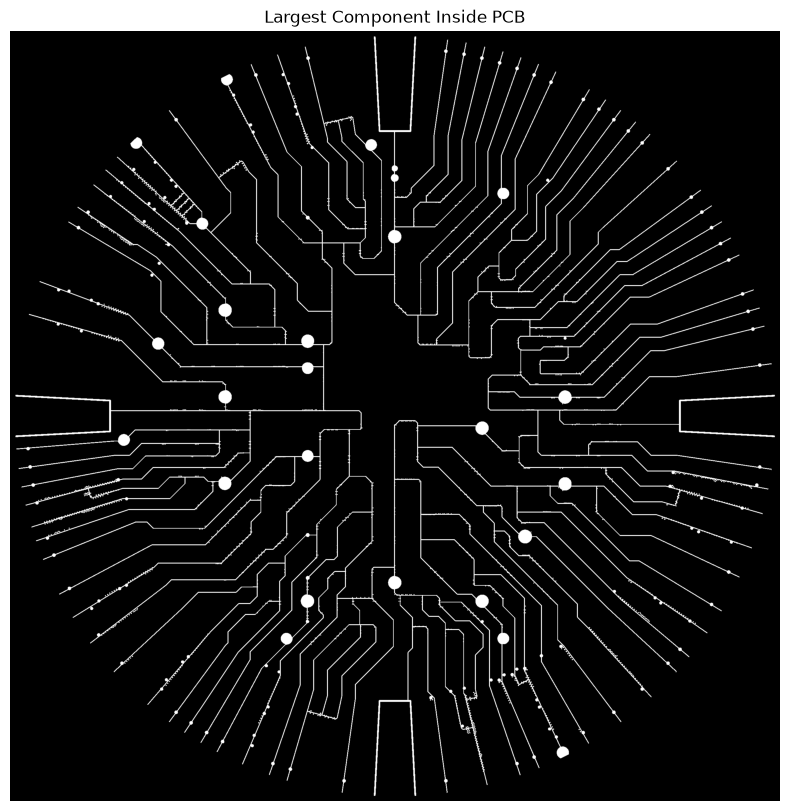

In [11]:
num_labels2, labels2, stats2, centroids2 = (
    cv2.connectedComponentsWithStats(
        pcb_copper.astype(np.uint8),
        connectivity=8
    )
)

areas2 = stats2[1:, cv2.CC_STAT_AREA]

print("PCB 내부 연결 성분 수:", num_labels2 - 1)

print("상위 10개 면적:")
print(np.sort(areas2)[-10:][::-1])

# 가장 큰 연결 성분 표시
largest_id2 = 1 + np.argmax(areas2)

largest_mask2 = labels2 == largest_id2

plt.figure(figsize=(10, 10))
plt.imshow(largest_mask2, cmap="gray")
plt.title("Largest Component Inside PCB")
plt.axis("off")
plt.show()

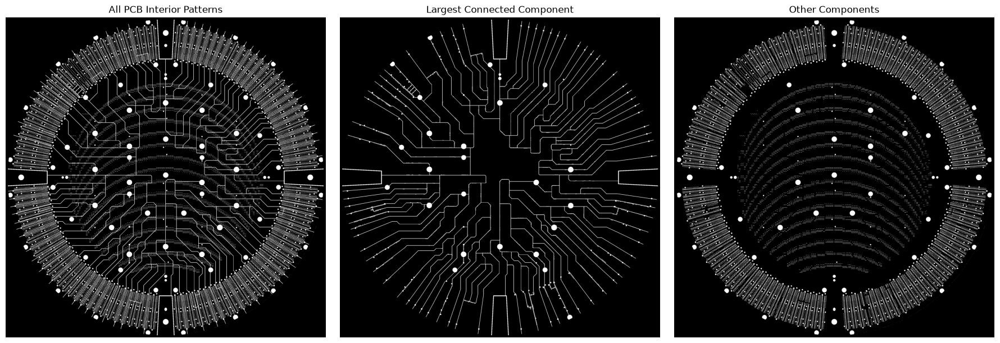

Largest component pixels: 252233
Other component pixels: 487964


In [12]:
# Cell 11 - 가장 큰 연결 성분과 나머지 영역 비교

main_component = labels2 == largest_id2
other_components = pcb_copper & ~main_component

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(pcb_copper, cmap="gray")
axes[0].set_title("All PCB Interior Patterns")

axes[1].imshow(main_component, cmap="gray")
axes[1].set_title("Largest Connected Component")

axes[2].imshow(other_components, cmap="gray")
axes[2].set_title("Other Components")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Largest component pixels:", np.sum(main_component))
print("Other component pixels:", np.sum(other_components))

Target pixels: 252233
Skeleton pixels: 65923


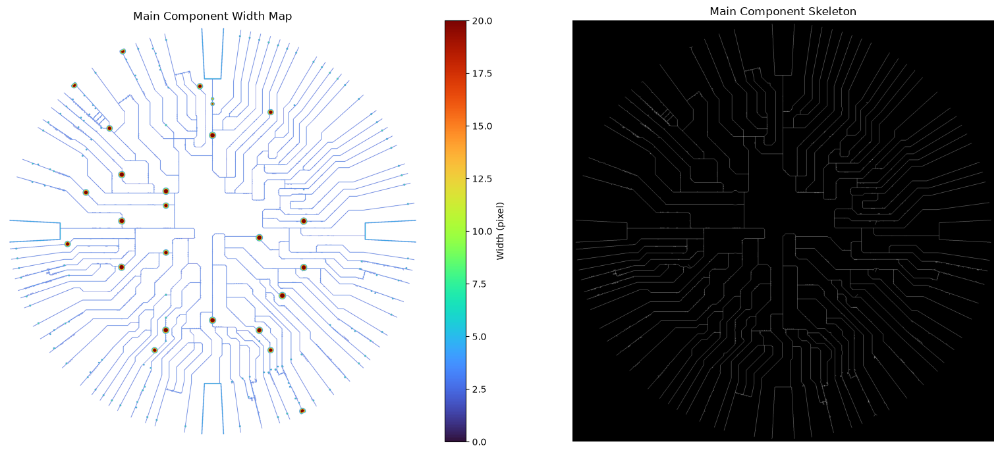

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize

# 가장 큰 연결 성분
target_mask = main_component.astype(np.uint8)

# Distance Transform
target_dist = cv2.distanceTransform(
    target_mask,
    cv2.DIST_L2,
    5
)

target_width = 2.0 * target_dist

# Skeleton
target_skeleton = skeletonize(target_mask > 0)

print("Target pixels:", np.sum(target_mask))
print("Skeleton pixels:", np.sum(target_skeleton))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

im = axes[0].imshow(
    np.where(target_mask > 0, target_width, np.nan),
    cmap="turbo",
    vmin=0,
    vmax=20
)
axes[0].set_title("Main Component Width Map")
plt.colorbar(im, ax=axes[0], label="Width (pixel)")

axes[1].imshow(target_skeleton, cmap="gray")
axes[1].set_title("Main Component Skeleton")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Endpoints: 973
Junction pixels: 4235


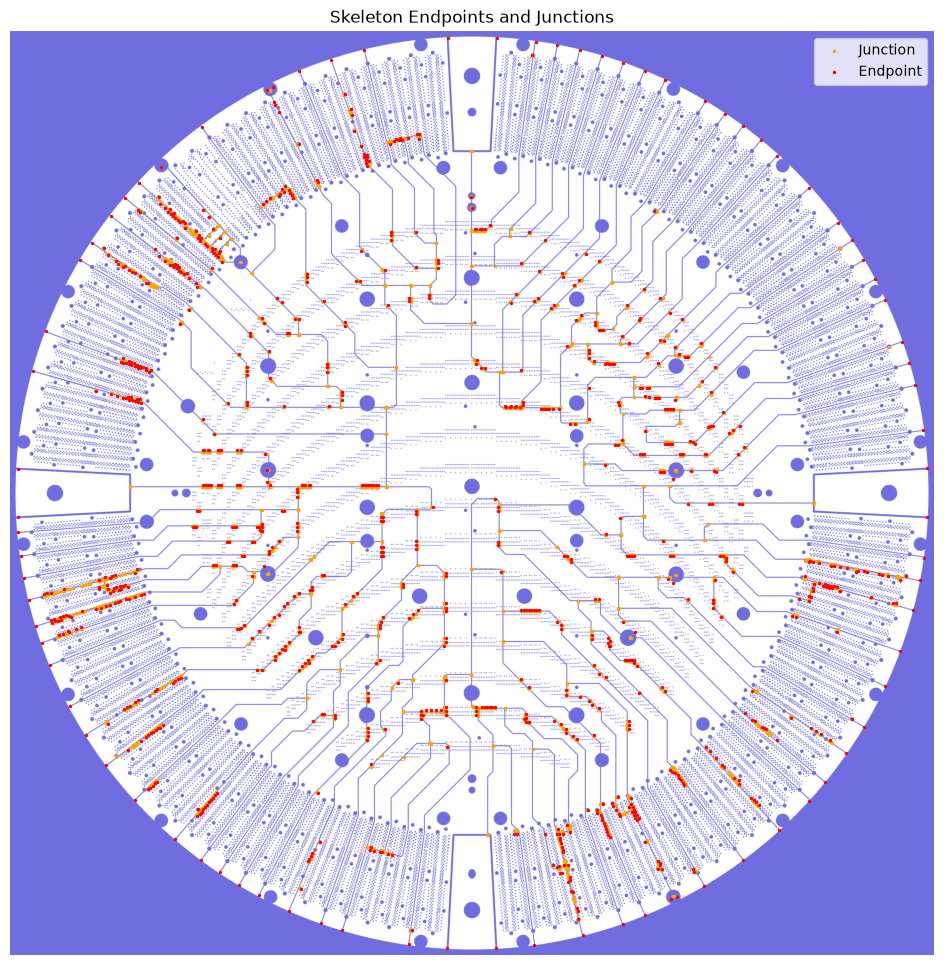

In [14]:
from scipy import ndimage as ndi

kernel = np.ones((3, 3), dtype=np.uint8)
kernel[1, 1] = 0

neighbors = ndi.convolve(
    target_skeleton.astype(np.uint8),
    kernel,
    mode="constant",
    cval=0
)

endpoints = target_skeleton & (neighbors == 1)
junctions = target_skeleton & (neighbors >= 3)

print("Endpoints:", np.sum(endpoints))
print("Junction pixels:", np.sum(junctions))

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(img_rgb)

jy, jx = np.where(junctions)
ey, ex = np.where(endpoints)

ax.scatter(jx, jy, s=2, c="orange", label="Junction")
ax.scatter(ex, ey, s=2, c="red", label="Endpoint")

ax.legend()
ax.set_title("Skeleton Endpoints and Junctions")
ax.axis("off")
plt.show()

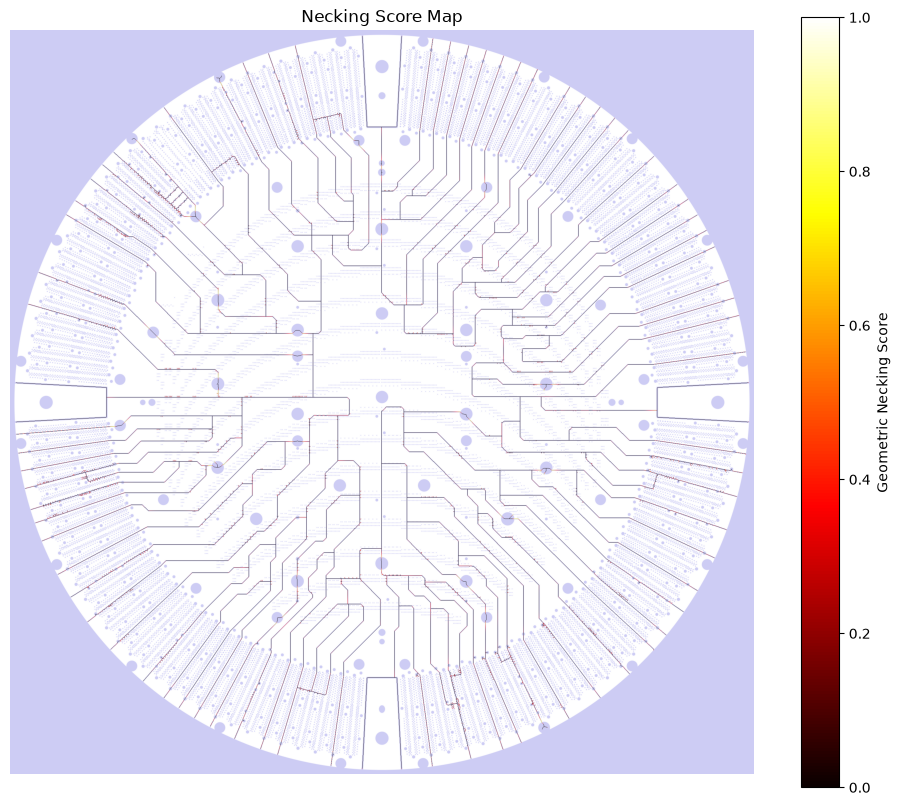

In [15]:
from scipy.ndimage import gaussian_filter

# 주변 폭을 계산할 공간적 범위
SIGMA = 15

skeleton_float = target_skeleton.astype(np.float32)

# Skeleton에서만 폭 데이터 사용
weighted_width = target_width * skeleton_float

# 주변 Skeleton 폭의 가중 평균
numerator = gaussian_filter(
    weighted_width.astype(np.float32),
    sigma=SIGMA
)

denominator = gaussian_filter(
    skeleton_float,
    sigma=SIGMA
)

reference_width = numerator / np.maximum(
    denominator, 1e-8
)

# 병목 점수
neck_score = np.zeros_like(target_width, dtype=np.float32)

valid = target_skeleton & (reference_width > 0)

neck_score[valid] = np.maximum(
    0,
    1 - target_width[valid] / reference_width[valid]
)

plt.figure(figsize=(12, 10))

plt.imshow(img_rgb, alpha=0.35)

score_img = np.ma.masked_where(
    ~target_skeleton,
    neck_score
)

plt.imshow(
    score_img,
    cmap="hot",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Geometric Necking Score")
plt.title("Necking Score Map")
plt.axis("off")
plt.show()

Candidate pixels: 3564


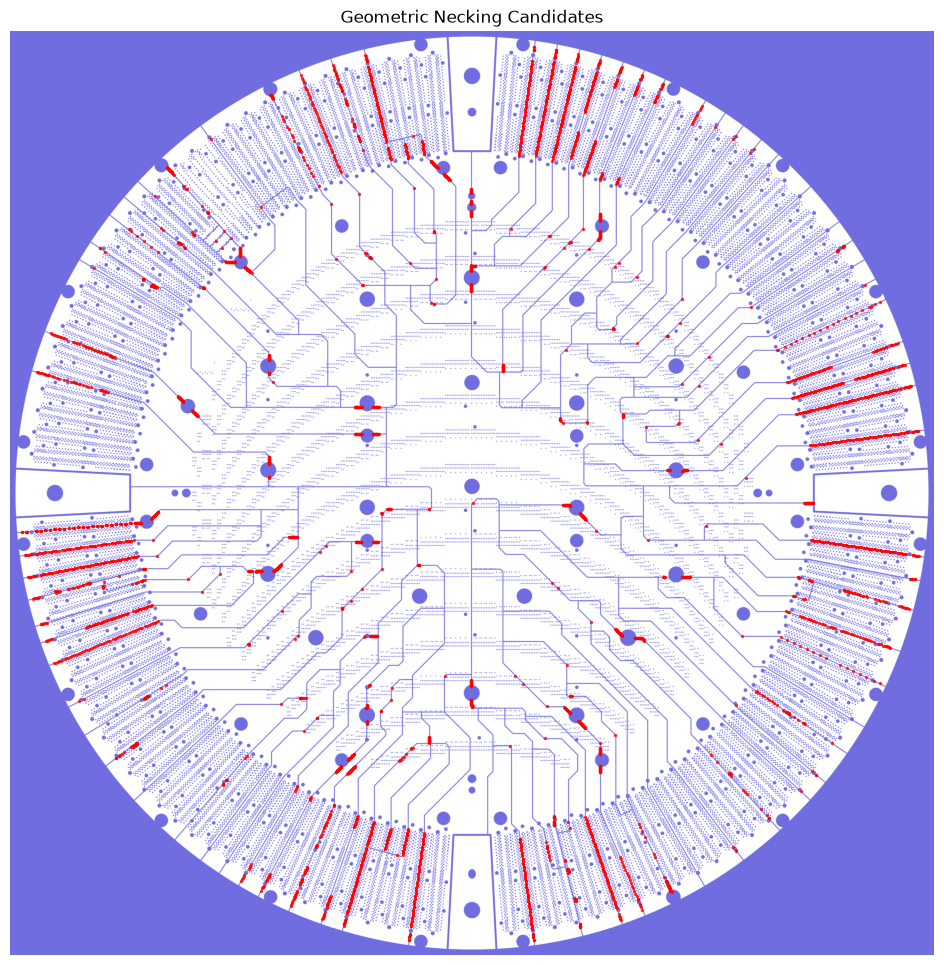

In [16]:
# 초기 실험 파라미터
SCORE_THRESHOLD = 0.30
MIN_WIDTH = 2.0
ENDPOINT_EXCLUSION = 10

# 끝점으로부터 거리
endpoint_distance = cv2.distanceTransform(
    (~endpoints).astype(np.uint8),
    cv2.DIST_L2,
    5
)

candidate_mask_v2 = (
    target_skeleton
    & (neck_score >= SCORE_THRESHOLD)
    & (target_width >= MIN_WIDTH)
    & (endpoint_distance > ENDPOINT_EXCLUSION)
)

print("Candidate pixels:", np.sum(candidate_mask_v2))

fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(img_rgb)

ys, xs = np.where(candidate_mask_v2)

ax.scatter(
    xs,
    ys,
    s=2,
    c="red",
    alpha=0.7
)

ax.set_title("Geometric Necking Candidates")
ax.axis("off")
plt.show()

In [17]:
import pandas as pd

num_c, candidate_labels, candidate_stats, _ = (
    cv2.connectedComponentsWithStats(
        candidate_mask_v2.astype(np.uint8),
        connectivity=8
    )
)

ys, xs = np.where(candidate_labels > 0)

if len(xs) == 0:
    df_neck = pd.DataFrame(
        columns=[
            "rank", "x_pixel", "y_pixel",
            "neck_score", "width_px", "region_size"
        ]
    )
else:
    region_ids = candidate_labels[ys, xs]
    scores = neck_score[ys, xs]

    # 점수가 높은 픽셀부터 정렬
    order = np.argsort(-scores)

    sorted_ids = region_ids[order]

    _, first_idx = np.unique(
        sorted_ids,
        return_index=True
    )

    selected_idx = order[first_idx]

    # 후보 영역 최소 크기
    MIN_REGION_SIZE = 5

    keep = (
        candidate_stats[
            region_ids[selected_idx],
            cv2.CC_STAT_AREA
        ] >= MIN_REGION_SIZE
    )

    selected_idx = selected_idx[keep]

    df_neck = pd.DataFrame({
        "x_pixel": xs[selected_idx],
        "y_pixel": ys[selected_idx],
        "neck_score": scores[selected_idx],
        "width_px": target_width[
            ys[selected_idx], xs[selected_idx]
        ],
        "region_size": candidate_stats[
            region_ids[selected_idx],
            cv2.CC_STAT_AREA
        ]
    })

    df_neck = df_neck.sort_values(
        "neck_score",
        ascending=False
    ).reset_index(drop=True)

    df_neck.insert(
        0,
        "rank",
        np.arange(1, len(df_neck) + 1)
    )

print("Candidate regions:", len(df_neck))
display(df_neck.head(20))

Candidate regions: 81


,rank,x_pixel,y_pixel,neck_score,width_px,region_size
0,1,1627,1575,0.837055,2.0,26
1,2,1714,2230,0.833113,2.0,19
2,3,1128,372,0.826207,2.0,18
3,4,671,1119,0.825285,2.0,20
4,5,597,580,0.817159,2.0,24
5,6,671,849,0.813914,2.0,13
6,7,649,1403,0.811589,2.0,16
7,8,858,1911,0.805893,2.0,17
8,9,671,891,0.804850,2.0,5
9,10,336,1277,0.802014,2.0,18


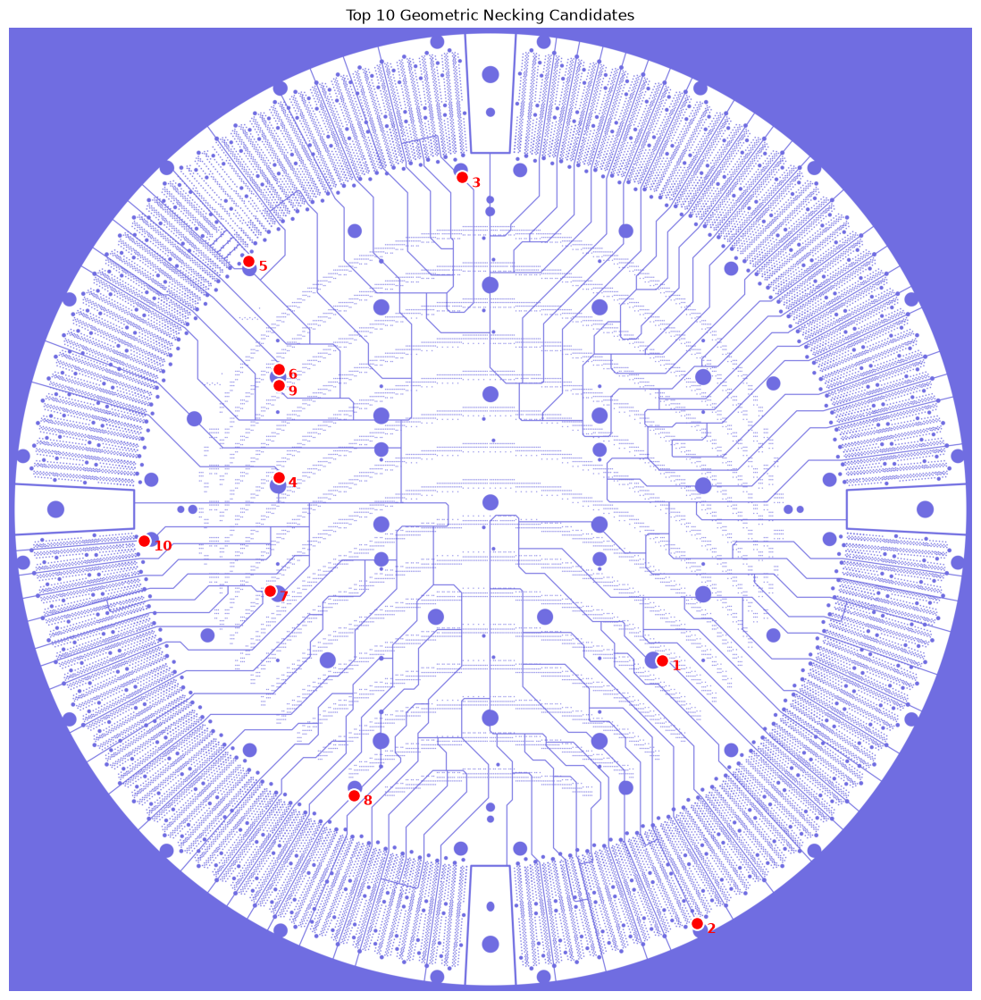

,rank,x_pixel,y_pixel,neck_score,width_px,region_size
0,1,1627,1575,0.837055,2.0,26
1,2,1714,2230,0.833113,2.0,19
2,3,1128,372,0.826207,2.0,18
3,4,671,1119,0.825285,2.0,20
4,5,597,580,0.817159,2.0,24
5,6,671,849,0.813914,2.0,13
6,7,649,1403,0.811589,2.0,16
7,8,858,1911,0.805893,2.0,17
8,9,671,891,0.804850,2.0,5
9,10,336,1277,0.802014,2.0,18


In [18]:
TOP_N = 10
MIN_DISTANCE = 40

selected_rows = []

for row in df_neck.itertuples(index=False):

    x = int(row.x_pixel)
    y = int(row.y_pixel)

    if all(
        np.hypot(
            x - p["x_pixel"],
            y - p["y_pixel"]
        ) >= MIN_DISTANCE
        for p in selected_rows
    ):
        selected_rows.append({
            "x_pixel": x,
            "y_pixel": y,
            "neck_score": float(row.neck_score),
            "width_px": float(row.width_px),
            "region_size": int(row.region_size)
        })

    if len(selected_rows) >= TOP_N:
        break

top_neck = pd.DataFrame(selected_rows)

if not top_neck.empty:
    top_neck.insert(
        0,
        "rank",
        np.arange(1, len(top_neck) + 1)
    )

fig, ax = plt.subplots(figsize=(14, 14))
ax.imshow(img_rgb)

for row in top_neck.itertuples(index=False):

    ax.scatter(
        row.x_pixel,
        row.y_pixel,
        s=110,
        c="red",
        edgecolors="white",
        linewidths=1.5
    )

    ax.annotate(
        str(row.rank),
        (row.x_pixel, row.y_pixel),
        xytext=(8, -8),
        textcoords="offset points",
        color="red",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title("Top 10 Geometric Necking Candidates")
ax.axis("off")

plt.savefig(
    OUTPUT_DIR / "necking_top10.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

display(top_neck)

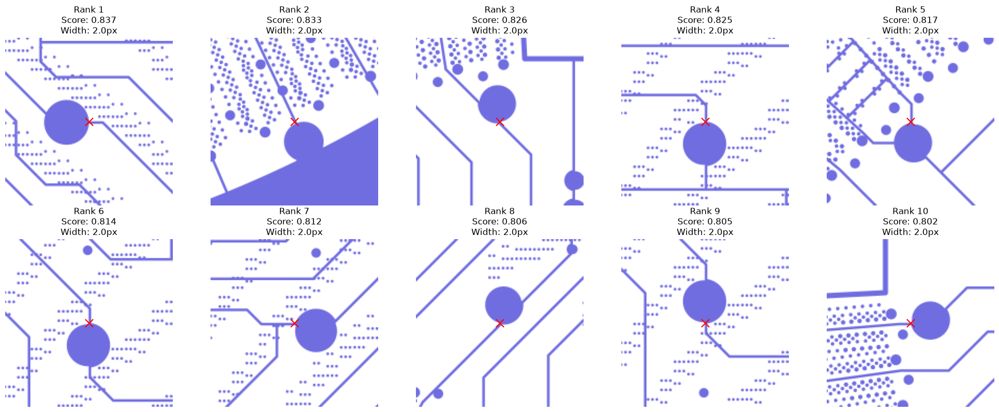

결과 저장 완료


In [19]:
import math

if not top_neck.empty:

    n = len(top_neck)
    cols = 5
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(20, 4 * rows),
        squeeze=False
    )

    CROP_SIZE = 80

    for i, row in enumerate(top_neck.itertuples(index=False)):

        x = int(row.x_pixel)
        y = int(row.y_pixel)

        x1 = max(0, x - CROP_SIZE)
        x2 = min(width, x + CROP_SIZE)
        y1 = max(0, y - CROP_SIZE)
        y2 = min(height, y + CROP_SIZE)

        ax = axes.flat[i]

        ax.imshow(
            img_rgb[y1:y2, x1:x2],
            extent=(x1, x2, y2, y1)
        )

        ax.scatter(
            x, y,
            c="red",
            marker="x",
            s=120
        )

        ax.set_title(
            f"Rank {row.rank}\n"
            f"Score: {row.neck_score:.3f}\n"
            f"Width: {row.width_px:.1f}px"
        )

        ax.axis("off")

    for i in range(n, rows * cols):
        axes.flat[i].axis("off")

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "necking_details.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    top_neck.to_csv(
        OUTPUT_DIR / "necking_top10.csv",
        index=False,
        encoding="utf-8-sig"
    )

    df_neck.to_csv(
        OUTPUT_DIR / "necking_all.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("결과 저장 완료")

else:
    print("현재 조건에서 병목 후보가 없습니다.")

In [20]:
import numpy as np
from collections import defaultdict

skel = target_skeleton.astype(bool)
H, W = skel.shape

ys, xs = np.where(skel)

# 픽셀 좌표 -> 노드 번호
pixel_ids = np.full((H, W), -1, dtype=np.int32)
pixel_ids[ys, xs] = np.arange(len(xs))

# 8방향 연결
directions = [
    (-1, -1), (-1, 0), (-1, 1),
    (0, -1),           (0, 1),
    (1, -1),  (1, 0),  (1, 1)
]

adj = [[] for _ in range(len(xs))]

for dy, dx in directions:
    src_y = ys + dy
    src_x = xs + dx

    valid = (
        (src_y >= 0) & (src_y < H) &
        (src_x >= 0) & (src_x < W)
    )

    src_ids = np.where(valid)[0]
    dst_ids = pixel_ids[
        src_y[valid],
        src_x[valid]
    ]

    keep = dst_ids >= 0

    for a, b in zip(src_ids[keep], dst_ids[keep]):
        adj[a].append(int(b))

degree = np.array([len(v) for v in adj])

print("Skeleton nodes:", len(xs))
print("Endpoints:", np.sum(degree == 1))
print("Normal nodes:", np.sum(degree == 2))
print("Junction nodes:", np.sum(degree >= 3))

Skeleton nodes: 65923
Endpoints: 973
Normal nodes: 60715
Junction nodes: 4235


In [21]:
import time

start = time.time()

visited_edges = set()
paths = []

def edge_key(a, b):
    return (min(a, b), max(a, b))

def trace_path(start_node, next_node):
    path = [start_node, next_node]

    visited_edges.add(edge_key(start_node, next_node))

    prev = start_node
    curr = next_node

    while degree[curr] == 2:
        options = [v for v in adj[curr] if v != prev]

        if not options:
            break

        nxt = options[0]
        key = edge_key(curr, nxt)

        if key in visited_edges:
            break

        visited_edges.add(key)
        path.append(nxt)

        prev, curr = curr, nxt

    return path

# 끝점 및 분기점에서 시작
special_nodes = np.where(degree != 2)[0]

for node in special_nodes:
    for neighbor in adj[node]:
        key = edge_key(int(node), neighbor)

        if key not in visited_edges:
            paths.append(
                trace_path(int(node), neighbor)
            )

# 남아 있는 폐곡선 및 미방문 간선 처리
for node in range(len(adj)):
    for neighbor in adj[node]:
        key = edge_key(node, neighbor)

        if key not in visited_edges:
            paths.append(
                trace_path(node, neighbor)
            )

print("Extracted paths:", len(paths))
print(f"Elapsed: {time.time()-start:.2f} s")

Extracted paths: 7358
Elapsed: 0.29 s


In [22]:
import pandas as pd

records = []

for path_id, path in enumerate(paths):

    if len(path) < 2:
        continue

    nodes = np.asarray(path, dtype=int)

    px = xs[nodes]
    py = ys[nodes]

    # 인접 픽셀 사이의 거리
    ds = np.hypot(
        np.diff(px),
        np.diff(py)
    )

    length_px = np.sum(ds)

    widths = target_width[py, px]

    # 각 간선의 평균 폭
    edge_width = (
        widths[:-1] + widths[1:]
    ) / 2

    edge_width = np.maximum(edge_width, 1e-6)

    # 기하학적 저항 지표
    resistance_index = np.sum(
        ds / edge_width
    )

    min_idx = np.argmin(widths)

    records.append({
        "path_id": path_id,
        "length_px": length_px,
        "min_width_px": np.min(widths),
        "mean_width_px": np.mean(widths),
        "max_width_px": np.max(widths),
        "resistance_index": resistance_index,
        "x_min": int(px[min_idx]),
        "y_min": int(py[min_idx]),
        "node_count": len(nodes)
    })

df_paths = pd.DataFrame(records)

# 너무 짧은 경로 제외
MIN_PATH_LENGTH = 20

df_paths = df_paths[
    df_paths["length_px"] >= MIN_PATH_LENGTH
].copy()

df_paths = df_paths.sort_values(
    "resistance_index",
    ascending=False
).reset_index(drop=True)

df_paths.insert(
    0,
    "rank",
    np.arange(1, len(df_paths) + 1)
)

print("Valid paths:", len(df_paths))
display(df_paths.head(20))

Valid paths: 455


,rank,path_id,length_px,min_width_px,mean_width_px,max_width_px,resistance_index,x_min,y_min,node_count
0,1,5441,722.288455,2.0,3.048305,10.393800,249.196303,746,1961,575
1,2,5932,647.813275,2.0,3.006752,7.193800,229.551997,1194,1836,561
2,3,5237,642.969696,2.0,3.281266,30.362797,226.175063,1627,1575,470
3,4,92,552.078210,2.0,3.461444,32.756596,224.651477,1068,272,510
4,5,2598,719.232539,2.0,3.527913,10.787600,218.879131,2372,1036,661
5,6,37,570.997041,2.0,2.774564,10.393800,215.276244,1805,182,473
6,7,15,636.742207,2.0,3.197747,11.200000,211.577609,1591,82,552
7,8,13,542.646753,2.0,2.730501,9.993799,208.651998,1536,64,484
8,9,5095,543.747258,2.0,2.833518,10.787600,203.309114,589,1549,488
9,10,4633,553.749350,2.0,2.943852,10.787600,193.040749,2181,1784,428


In [23]:
from scipy.ndimage import uniform_filter1d

NECK_THRESHOLD = 0.30
REFERENCE_WINDOW = 31
MIN_NECK_LENGTH = 3.0

neck_records = []

valid_path_ids = set(df_paths["path_id"])

for path_id, path in enumerate(paths):

    if path_id not in valid_path_ids:
        continue

    nodes = np.asarray(path, dtype=int)
    px = xs[nodes]
    py = ys[nodes]

    widths = target_width[py, px].astype(float)

    if len(widths) < 5:
        continue

    # 동일 경로에서 주변 폭 계산
    ref_width = uniform_filter1d(
        widths,
        size=REFERENCE_WINDOW,
        mode="nearest"
    )

    score = np.maximum(
        0,
        1 - widths / np.maximum(ref_width, 1e-6)
    )

    # 병목 조건
    neck_mask = score >= NECK_THRESHOLD

    # 연속된 병목 구간 추출
    padded = np.r_[False, neck_mask, False]
    changes = np.diff(padded.astype(int))

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    for start_idx, end_idx in zip(starts, ends):

        # 병목 구간 길이
        segment_x = px[start_idx:end_idx]
        segment_y = py[start_idx:end_idx]

        if len(segment_x) < 2:
            continue

        ds = np.hypot(
            np.diff(segment_x),
            np.diff(segment_y)
        )

        neck_length = np.sum(ds)

        if neck_length < MIN_NECK_LENGTH:
            continue

        # 가장 좁아지는 지점
        local_idx = np.argmax(
            score[start_idx:end_idx]
        )

        idx = start_idx + local_idx

        neck_records.append({
            "path_id": path_id,
            "x_pixel": int(px[idx]),
            "y_pixel": int(py[idx]),
            "neck_score": float(score[idx]),
            "min_width_px": float(
                np.min(widths[start_idx:end_idx])
            ),
            "reference_width_px": float(ref_width[idx]),
            "neck_length_px": float(neck_length),
            "path_resistance_index": float(
                df_paths.loc[
                    df_paths["path_id"] == path_id,
                    "resistance_index"
                ].iloc[0]
            )
        })

df_neck_path = pd.DataFrame(neck_records)

if not df_neck_path.empty:
    df_neck_path = df_neck_path.sort_values(
        ["neck_score", "neck_length_px"],
        ascending=[False, False]
    ).reset_index(drop=True)

    df_neck_path.insert(
        0, "rank",
        np.arange(1, len(df_neck_path) + 1)
    )

print("Detected neck regions:", len(df_neck_path))
display(df_neck_path.head(20))

Detected neck regions: 154


,rank,path_id,x_pixel,y_pixel,neck_score,min_width_px,reference_width_px,neck_length_px,path_resistance_index
0,1,3838,659,1391,0.815974,2.0,10.868018,7.656854,2.602610
1,2,2902,1722,1160,0.808262,2.0,10.430909,6.414214,2.514392
2,3,6295,858,1911,0.805827,2.0,10.300077,15.142136,58.402000
3,4,92,1128,372,0.803367,2.0,10.171245,15.142136,224.651477
4,5,3991,1722,1431,0.802032,2.0,10.102626,5.828427,2.186508
5,6,7272,1714,2230,0.793468,2.0,9.683722,15.899495,21.815333
6,7,3938,649,1403,0.781978,2.0,9.173394,14.000000,8.688592
7,8,5237,1627,1575,0.779061,2.0,9.052264,14.000000,226.175063
8,9,2857,671,1161,0.778696,2.0,9.037361,13.414214,6.260324
9,10,1732,671,849,0.778429,2.0,9.026458,14.000000,16.578659


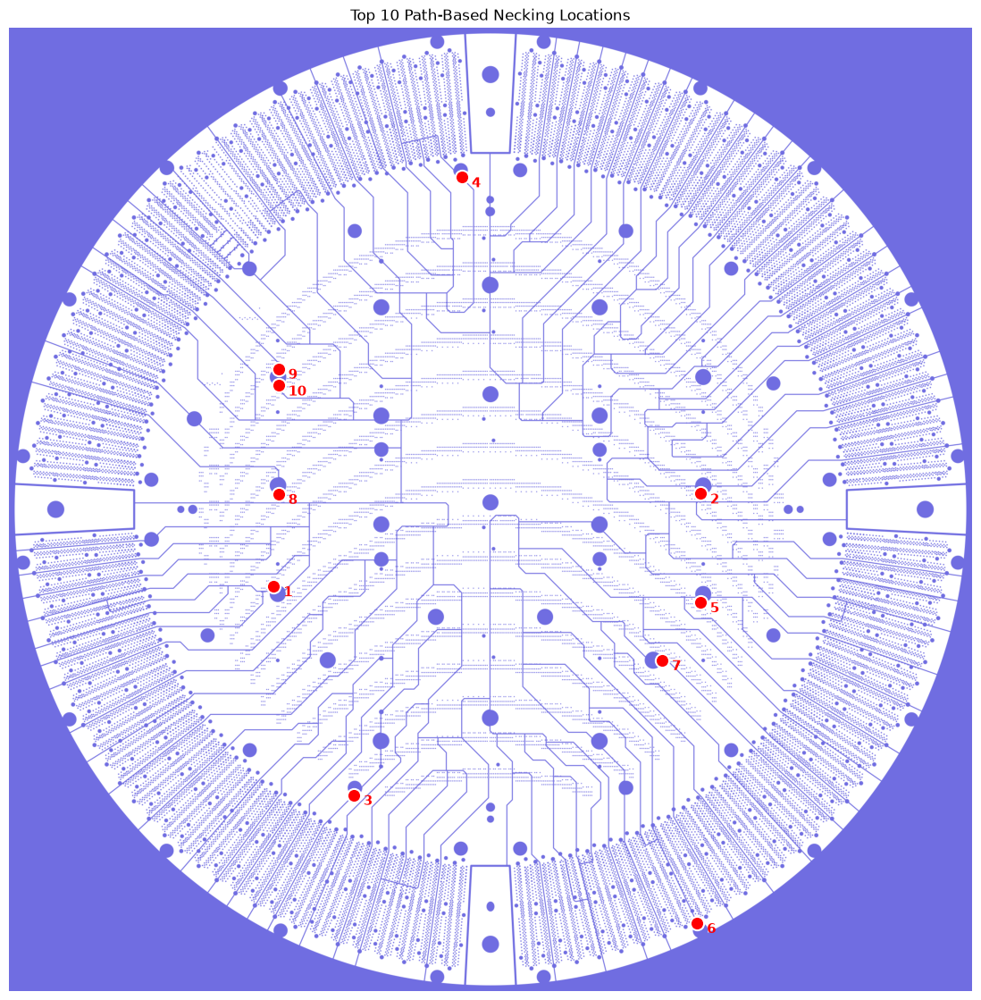

,rank,x_pixel,y_pixel,path_id,neck_score,min_width_px,neck_length_px,path_resistance_index
0,1,659,1391,3838,0.815974,2.0,7.656854,2.602610
1,2,1722,1160,2902,0.808262,2.0,6.414214,2.514392
2,3,858,1911,6295,0.805827,2.0,15.142136,58.402000
3,4,1128,372,92,0.803367,2.0,15.142136,224.651477
4,5,1722,1431,3991,0.802032,2.0,5.828427,2.186508
5,6,1714,2230,7272,0.793468,2.0,15.899495,21.815333
6,7,1627,1575,5237,0.779061,2.0,14.000000,226.175063
7,8,671,1161,2857,0.778696,2.0,13.414214,6.260324
8,9,671,849,1732,0.778429,2.0,14.000000,16.578659
9,10,671,891,1732,0.778424,2.0,13.414214,16.578659


In [24]:
TOP_N = 10
MIN_DISTANCE = 40

selected = []

if not df_neck_path.empty:

    for row in df_neck_path.itertuples(index=False):

        x, y = row.x_pixel, row.y_pixel

        if all(
            np.hypot(
                x - p["x_pixel"],
                y - p["y_pixel"]
            ) >= MIN_DISTANCE
            for p in selected
        ):
            selected.append({
                "x_pixel": x,
                "y_pixel": y,
                "path_id": row.path_id,
                "neck_score": row.neck_score,
                "min_width_px": row.min_width_px,
                "neck_length_px": row.neck_length_px,
                "path_resistance_index":
                    row.path_resistance_index
            })

        if len(selected) >= TOP_N:
            break

top_path_necks = pd.DataFrame(selected)

if not top_path_necks.empty:
    top_path_necks.insert(
        0, "rank",
        np.arange(1, len(top_path_necks) + 1)
    )

fig, ax = plt.subplots(figsize=(14, 14))
ax.imshow(img_rgb)

for row in top_path_necks.itertuples(index=False):

    ax.scatter(
        row.x_pixel,
        row.y_pixel,
        s=120,
        c="red",
        edgecolors="white",
        linewidths=1.5
    )

    ax.annotate(
        str(row.rank),
        (row.x_pixel, row.y_pixel),
        xytext=(8, -8),
        textcoords="offset points",
        fontsize=11,
        color="red",
        fontweight="bold"
    )

ax.set_title("Top 10 Path-Based Necking Locations")
ax.axis("off")

plt.savefig(
    OUTPUT_DIR / "path_necking_top10.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

display(top_path_necks)

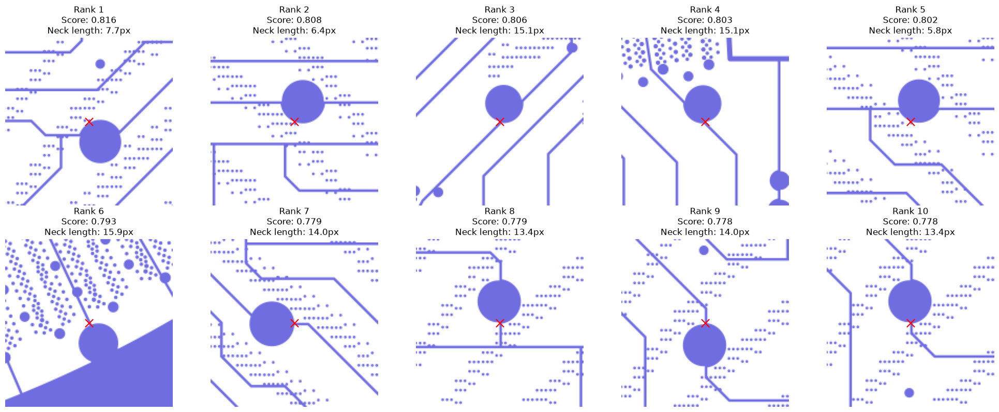

분석 결과 저장 완료


In [25]:
import math

if not top_path_necks.empty:

    n = len(top_path_necks)
    cols = 5
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(20, 4 * rows),
        squeeze=False
    )

    CROP_SIZE = 80

    for i, row in enumerate(
        top_path_necks.itertuples(index=False)
    ):

        x = int(row.x_pixel)
        y = int(row.y_pixel)

        x1 = max(0, x - CROP_SIZE)
        x2 = min(width, x + CROP_SIZE)
        y1 = max(0, y - CROP_SIZE)
        y2 = min(height, y + CROP_SIZE)

        ax = axes.flat[i]

        ax.imshow(
            img_rgb[y1:y2, x1:x2],
            extent=(x1, x2, y2, y1)
        )

        ax.scatter(x, y, c="red", marker="x", s=120)

        ax.set_title(
            f"Rank {row.rank}\n"
            f"Score: {row.neck_score:.3f}\n"
            f"Neck length: {row.neck_length_px:.1f}px"
        )

        ax.axis("off")

    for i in range(n, rows * cols):
        axes.flat[i].axis("off")

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "path_necking_details.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

# CSV 저장
df_paths.to_csv(
    OUTPUT_DIR / "path_resistance.csv",
    index=False,
    encoding="utf-8-sig"
)

df_neck_path.to_csv(
    OUTPUT_DIR / "path_necking_all.csv",
    index=False,
    encoding="utf-8-sig"
)

top_path_necks.to_csv(
    OUTPUT_DIR / "path_necking_top10.csv",
    index=False,
    encoding="utf-8-sig"
)

print("분석 결과 저장 완료")

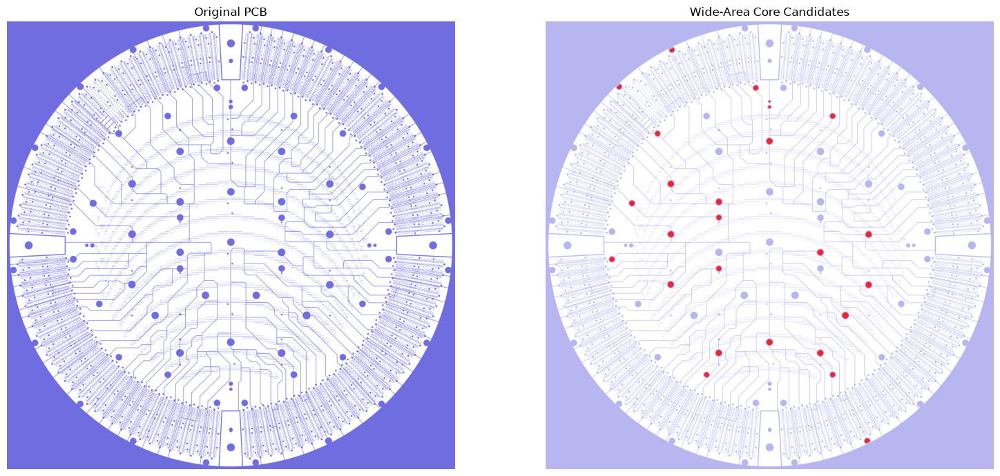

Wide-area core pixels: 16783


In [26]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 이전 Cell 12에서 계산한 값 사용
# target_mask, target_dist, target_width

PAD_WIDTH_THRESHOLD = 10.0

# 폭이 일정 수준 이상인 내부 영역
pad_core = (
    (target_width >= PAD_WIDTH_THRESHOLD)
    & (target_mask > 0)
)

# Pad 중심 후보 표시
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(img_rgb)
axes[0].set_title("Original PCB")

axes[1].imshow(img_rgb, alpha=0.5)
axes[1].imshow(
    np.ma.masked_where(~pad_core, pad_core),
    cmap="autumn",
    alpha=0.8
)
axes[1].set_title("Wide-Area Core Candidates")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Wide-area core pixels:", np.sum(pad_core))

In [27]:
from scipy.ndimage import distance_transform_edt

# 넓은 영역까지의 거리
distance_to_pad = distance_transform_edt(~pad_core)

# 기존 경로 기반 병목 결과 복사
df_classified = df_neck_path.copy()

if not df_classified.empty:

    px = df_classified["x_pixel"].to_numpy(dtype=int)
    py = df_classified["y_pixel"].to_numpy(dtype=int)

    df_classified["distance_to_pad_px"] = (
        distance_to_pad[py, px]
    )

display(df_classified.head(20))

,rank,path_id,x_pixel,y_pixel,neck_score,min_width_px,reference_width_px,neck_length_px,path_resistance_index,distance_to_pad_px
0,1,3838,659,1391,0.815974,2.0,10.868018,7.656854,2.602610,5.000000
1,2,2902,1722,1160,0.808262,2.0,10.430909,6.414214,2.514392,5.000000
2,3,6295,858,1911,0.805827,2.0,10.300077,15.142136,58.402000,5.000000
3,4,92,1128,372,0.803367,2.0,10.171245,15.142136,224.651477,5.000000
4,5,3991,1722,1431,0.802032,2.0,10.102626,5.828427,2.186508,5.000000
5,6,7272,1714,2230,0.793468,2.0,9.683722,15.899495,21.815333,6.403124
6,7,3938,649,1403,0.781978,2.0,9.173394,14.000000,8.688592,5.099020
7,8,5237,1627,1575,0.779061,2.0,9.052264,14.000000,226.175063,5.000000
8,9,2857,671,1161,0.778696,2.0,9.037361,13.414214,6.260324,5.000000
9,10,1732,671,849,0.778429,2.0,9.026458,14.000000,16.578659,5.000000


In [28]:
PAD_DISTANCE_THRESHOLD = 12.0

def classify_neck(distance):

    if distance <= PAD_DISTANCE_THRESHOLD:
        return "Pad-to-Trace"

    return "Trace-to-Trace"

df_classified["type"] = (
    df_classified["distance_to_pad_px"]
    .apply(classify_neck)
)

print(df_classified["type"].value_counts())

display(
    df_classified[
        [
            "rank",
            "x_pixel",
            "y_pixel",
            "neck_score",
            "neck_length_px",
            "distance_to_pad_px",
            "type"
        ]
    ].head(20)
)

type
Pad-to-Trace      101
Trace-to-Trace     53
Name: count, dtype: int64


,rank,x_pixel,y_pixel,neck_score,neck_length_px,distance_to_pad_px,type
0,1,659,1391,0.815974,7.656854,5.000000,Pad-to-Trace
1,2,1722,1160,0.808262,6.414214,5.000000,Pad-to-Trace
2,3,858,1911,0.805827,15.142136,5.000000,Pad-to-Trace
3,4,1128,372,0.803367,15.142136,5.000000,Pad-to-Trace
4,5,1722,1431,0.802032,5.828427,5.000000,Pad-to-Trace
5,6,1714,2230,0.793468,15.899495,6.403124,Pad-to-Trace
6,7,649,1403,0.781978,14.000000,5.099020,Pad-to-Trace
7,8,1627,1575,0.779061,14.000000,5.000000,Pad-to-Trace
8,9,671,1161,0.778696,13.414214,5.000000,Pad-to-Trace
9,10,671,849,0.778429,14.000000,5.000000,Pad-to-Trace


In [29]:
pad_necks = df_classified[
    df_classified["type"] == "Pad-to-Trace"
].copy()

trace_necks = df_classified[
    df_classified["type"] == "Trace-to-Trace"
].copy()

pad_necks = pad_necks.sort_values(
    ["neck_score", "neck_length_px"],
    ascending=[False, False]
).reset_index(drop=True)

trace_necks = trace_necks.sort_values(
    ["neck_score", "neck_length_px"],
    ascending=[False, False]
).reset_index(drop=True)

pad_necks["type_rank"] = np.arange(
    1, len(pad_necks) + 1
)

trace_necks["type_rank"] = np.arange(
    1, len(trace_necks) + 1
)

print("Pad-to-Trace candidates:", len(pad_necks))
print("Trace-to-Trace candidates:", len(trace_necks))

print("\nPad-to-Trace Top 10")
display(pad_necks.head(10))

print("\nTrace-to-Trace Top 10")
display(trace_necks.head(10))

Pad-to-Trace candidates: 101
Trace-to-Trace candidates: 53

Pad-to-Trace Top 10


,rank,path_id,x_pixel,y_pixel,neck_score,min_width_px,reference_width_px,neck_length_px,path_resistance_index,distance_to_pad_px,type,type_rank
0,1,3838,659,1391,0.815974,2.0,10.868018,7.656854,2.602610,5.000000,Pad-to-Trace,1
1,2,2902,1722,1160,0.808262,2.0,10.430909,6.414214,2.514392,5.000000,Pad-to-Trace,2
2,3,6295,858,1911,0.805827,2.0,10.300077,15.142136,58.402000,5.000000,Pad-to-Trace,3
3,4,92,1128,372,0.803367,2.0,10.171245,15.142136,224.651477,5.000000,Pad-to-Trace,4
4,5,3991,1722,1431,0.802032,2.0,10.102626,5.828427,2.186508,5.000000,Pad-to-Trace,5
5,6,7272,1714,2230,0.793468,2.0,9.683722,15.899495,21.815333,6.403124,Pad-to-Trace,6
6,7,3938,649,1403,0.781978,2.0,9.173394,14.000000,8.688592,5.099020,Pad-to-Trace,7
7,8,5237,1627,1575,0.779061,2.0,9.052264,14.000000,226.175063,5.000000,Pad-to-Trace,8
8,9,2857,671,1161,0.778696,2.0,9.037361,13.414214,6.260324,5.000000,Pad-to-Trace,9
9,10,1732,671,849,0.778429,2.0,9.026458,14.000000,16.578659,5.000000,Pad-to-Trace,10



Trace-to-Trace Top 10


,rank,path_id,x_pixel,y_pixel,neck_score,min_width_px,reference_width_px,neck_length_px,path_resistance_index,distance_to_pad_px,type,type_rank
0,36,82,900,263,0.624373,2.0,5.324432,3.828427,13.886018,181.176709,Trace-to-Trace,1
1,38,7168,1407,2171,0.621765,2.0,5.287722,7.242641,6.980174,133.645052,Trace-to-Trace,2
2,40,6296,1473,1845,0.619896,2.0,5.261716,8.071068,50.620768,52.000000,Trace-to-Trace,3
3,46,6592,793,1978,0.609557,2.0,5.122380,7.656854,124.907733,49.769469,Trace-to-Trace,4
4,57,5986,2033,1781,0.599226,2.0,4.990348,4.414214,19.971617,153.117602,Trace-to-Trace,5
5,61,7016,796,2114,0.594027,2.0,4.926432,5.828427,10.113579,13.601471,Trace-to-Trace,6
6,63,1616,266,845,0.586513,2.0,4.836910,3.414214,72.463376,219.968180,Trace-to-Trace,7
7,65,75,893,243,0.568077,2.0,4.630458,3.414214,12.164419,162.806634,Trace-to-Trace,8
8,70,47,698,207,0.554240,2.0,4.486722,4.000000,5.544487,47.413078,Trace-to-Trace,9
9,71,3216,43,1300,0.551883,2.0,4.463116,3.000000,140.575443,13.038405,Trace-to-Trace,10


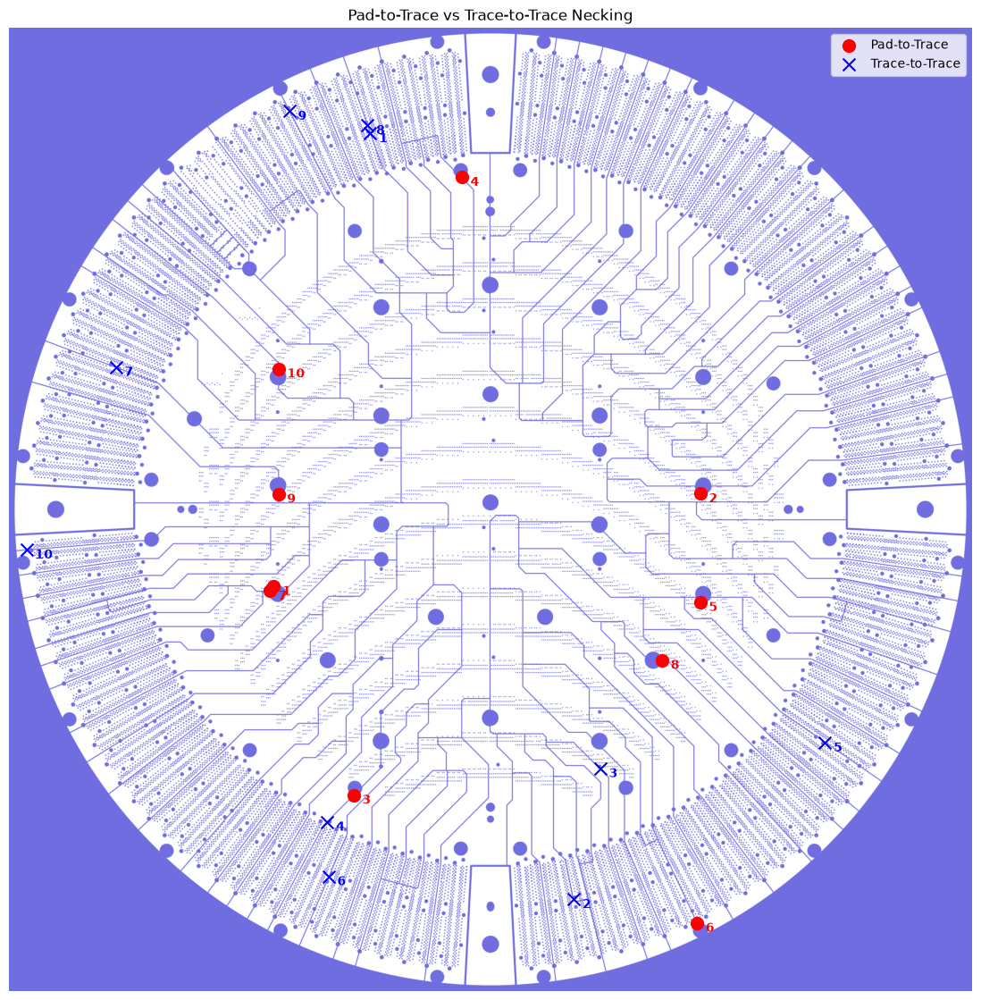

In [30]:
TOP_N = 10

fig, ax = plt.subplots(figsize=(14, 14))
ax.imshow(img_rgb)

for data, color, marker, name in [
    (pad_necks, "red", "o", "Pad-to-Trace"),
    (trace_necks, "blue", "x", "Trace-to-Trace")
]:

    top = data.head(TOP_N)

    ax.scatter(
        top["x_pixel"],
        top["y_pixel"],
        s=100,
        c=color,
        marker=marker,
        label=name
    )

    for row in top.itertuples(index=False):
        ax.annotate(
            str(row.type_rank),
            (row.x_pixel, row.y_pixel),
            xytext=(7, -7),
            textcoords="offset points",
            color=color,
            fontsize=10,
            fontweight="bold"
        )

ax.legend()
ax.set_title("Pad-to-Trace vs Trace-to-Trace Necking")
ax.axis("off")

plt.savefig(
    OUTPUT_DIR / "classified_necking.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

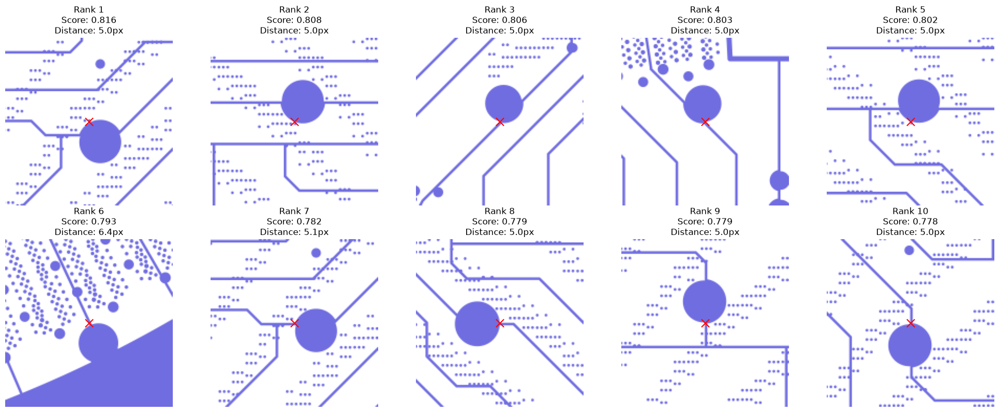

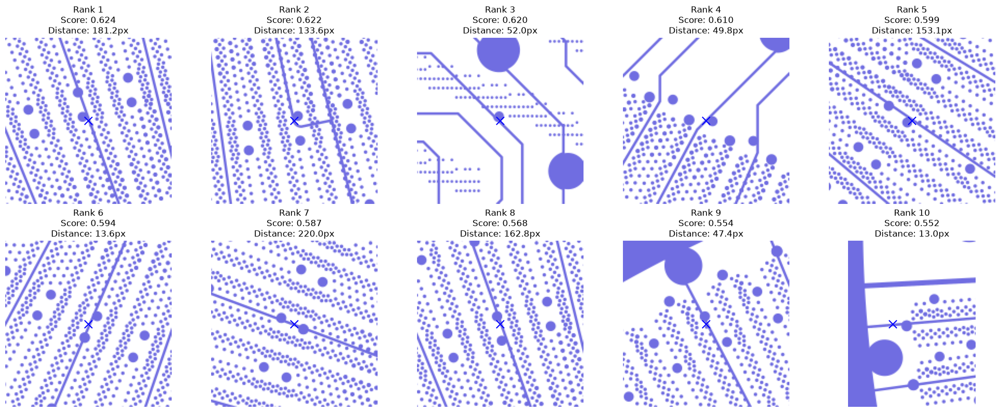

분류 및 결과 저장 완료


In [31]:
import math

groups = [
    ("Pad-to-Trace", pad_necks),
    ("Trace-to-Trace", trace_necks)
]

for group_name, data in groups:

    top = data.head(10)

    if top.empty:
        continue

    n = len(top)
    cols = 5
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(20, 4 * rows),
        squeeze=False
    )

    for i, row in enumerate(top.itertuples(index=False)):

        x = int(row.x_pixel)
        y = int(row.y_pixel)

        crop_size = 80

        x1 = max(0, x - crop_size)
        x2 = min(width, x + crop_size)
        y1 = max(0, y - crop_size)
        y2 = min(height, y + crop_size)

        ax = axes.flat[i]

        ax.imshow(
            img_rgb[y1:y2, x1:x2],
            extent=(x1, x2, y2, y1)
        )

        ax.scatter(
            x, y,
            c="red" if group_name == "Pad-to-Trace" else "blue",
            marker="x",
            s=120
        )

        ax.set_title(
            f"Rank {row.type_rank}\n"
            f"Score: {row.neck_score:.3f}\n"
            f"Distance: {row.distance_to_pad_px:.1f}px"
        )

        ax.axis("off")

    for i in range(n, rows * cols):
        axes.flat[i].axis("off")

    plt.tight_layout()

    filename = group_name.lower().replace("-", "_")

    plt.savefig(
        OUTPUT_DIR / f"{filename}_details.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

# CSV 저장
df_classified.to_csv(
    OUTPUT_DIR / "classified_all.csv",
    index=False,
    encoding="utf-8-sig"
)

pad_necks.to_csv(
    OUTPUT_DIR / "pad_to_trace.csv",
    index=False,
    encoding="utf-8-sig"
)

trace_necks.to_csv(
    OUTPUT_DIR / "trace_to_trace.csv",
    index=False,
    encoding="utf-8-sig"
)

print("분류 및 결과 저장 완료")

Local mask: (200, 200)
Conductive pixels: 4023


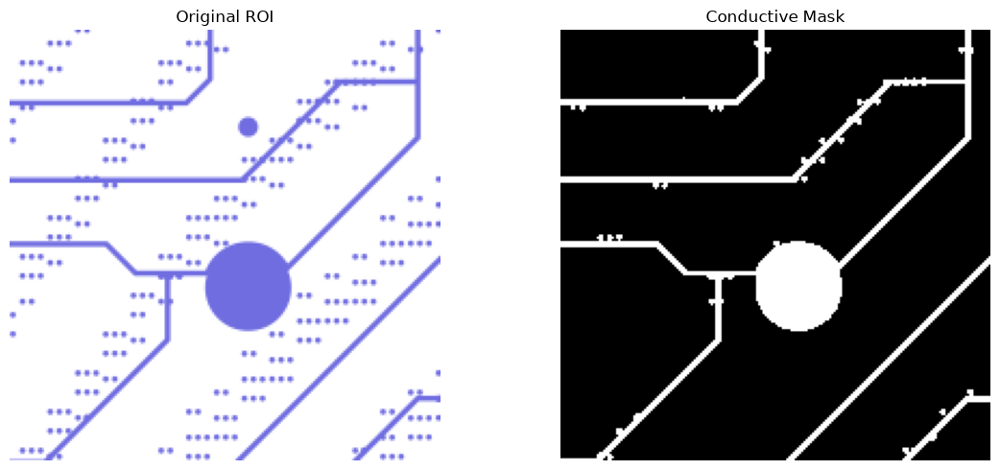

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from scipy import sparse
from scipy.sparse.linalg import spsolve

# 기존 Cell 12에서 사용한 연결 성분
conductive_mask = target_mask.astype(bool)

# 분석할 병목 후보
candidate = top_path_necks.iloc[0]

cx = int(candidate["x_pixel"])
cy = int(candidate["y_pixel"])

CROP_RADIUS = 100

x1 = max(0, cx - CROP_RADIUS)
x2 = min(width, cx + CROP_RADIUS)

y1 = max(0, cy - CROP_RADIUS)
y2 = min(height, cy + CROP_RADIUS)

local_mask = conductive_mask[y1:y2, x1:x2]

local_rgb = img_rgb[y1:y2, x1:x2]

print("Local mask:", local_mask.shape)
print("Conductive pixels:", np.sum(local_mask))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(local_rgb)
axes[0].set_title("Original ROI")

axes[1].imshow(local_mask, cmap="gray")
axes[1].set_title("Conductive Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

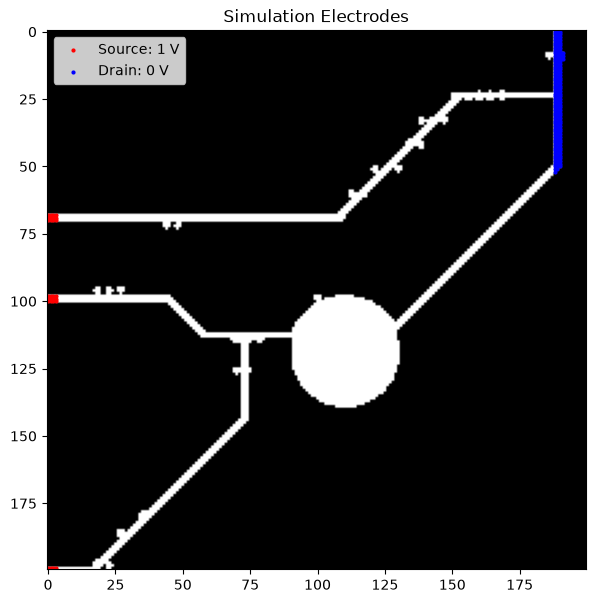

In [33]:
num, roi_labels, roi_stats, _ = (
    cv2.connectedComponentsWithStats(
        local_mask.astype(np.uint8),
        connectivity=4
    )
)

if num <= 1:
    raise ValueError("ROI에 전도 영역이 없습니다.")

largest = 1 + np.argmax(
    roi_stats[1:, cv2.CC_STAT_AREA]
)

roi_conductor = roi_labels == largest

yy, xx = np.where(roi_conductor)

left_x = np.min(xx)
right_x = np.max(xx)

if left_x == right_x:
    raise ValueError("전극 사이의 수평 거리가 없습니다.")

# 좌우 끝부분의 전극
electrode_width = 3

source_mask = (
    roi_conductor &
    (np.indices(roi_conductor.shape)[1] <= left_x + electrode_width)
)

drain_mask = (
    roi_conductor &
    (np.indices(roi_conductor.shape)[1] >= right_x - electrode_width)
)

# 전극이 겹치지 않도록 확인
if np.any(source_mask & drain_mask):
    raise ValueError("Source와 Drain 전극이 겹칩니다.")

fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(roi_conductor, cmap="gray")

sy, sx = np.where(source_mask)
dy, dx = np.where(drain_mask)

ax.scatter(sx, sy, s=4, c="red", label="Source: 1 V")
ax.scatter(dx, dy, s=4, c="blue", label="Drain: 0 V")

ax.legend()
ax.set_title("Simulation Electrodes")
plt.show()

In [34]:
from scipy.sparse import lil_matrix

H, W = roi_conductor.shape

node_map = np.full((H, W), -1, dtype=int)

ys, xs = np.where(roi_conductor)

N = len(xs)

node_map[ys, xs] = np.arange(N)

A = lil_matrix((N, N), dtype=float)
b = np.zeros(N)

source_nodes = set(node_map[source_mask])
drain_nodes = set(node_map[drain_mask])

for i, (y, x) in enumerate(zip(ys, xs)):

    if i in source_nodes:
        A[i, i] = 1.0
        b[i] = 1.0
        continue

    if i in drain_nodes:
        A[i, i] = 1.0
        b[i] = 0.0
        continue

    neighbors = []

    for dy, dx in [
        (-1, 0), (1, 0),
        (0, -1), (0, 1)
    ]:

        ny = y + dy
        nx = x + dx

        if 0 <= ny < H and 0 <= nx < W:
            j = node_map[ny, nx]

            if j >= 0:
                neighbors.append(j)

    A[i, i] = len(neighbors)

    for j in neighbors:
        A[i, j] = -1.0

A = A.tocsr()

print("Network nodes:", N)
print("Matrix shape:", A.shape)
print("Non-zero elements:", A.nnz)

Network nodes: 3063
Matrix shape: (3063, 3063)
Non-zero elements: 13077


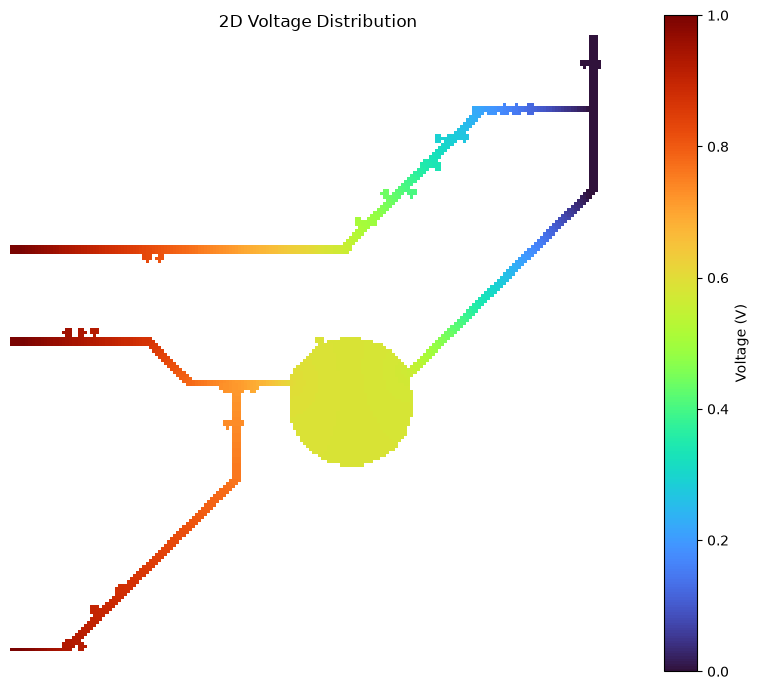

Minimum voltage: 0.0
Maximum voltage: 1.0


In [35]:
V_nodes = spsolve(A, b)

voltage_map = np.full(
    (H, W),
    np.nan,
    dtype=float
)

voltage_map[ys, xs] = V_nodes

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(
    voltage_map,
    cmap="turbo",
    vmin=0,
    vmax=1
)

plt.colorbar(im, ax=ax, label="Voltage (V)")

ax.set_title("2D Voltage Distribution")
ax.axis("off")

plt.tight_layout()
plt.show()

print("Minimum voltage:", np.nanmin(voltage_map))
print("Maximum voltage:", np.nanmax(voltage_map))

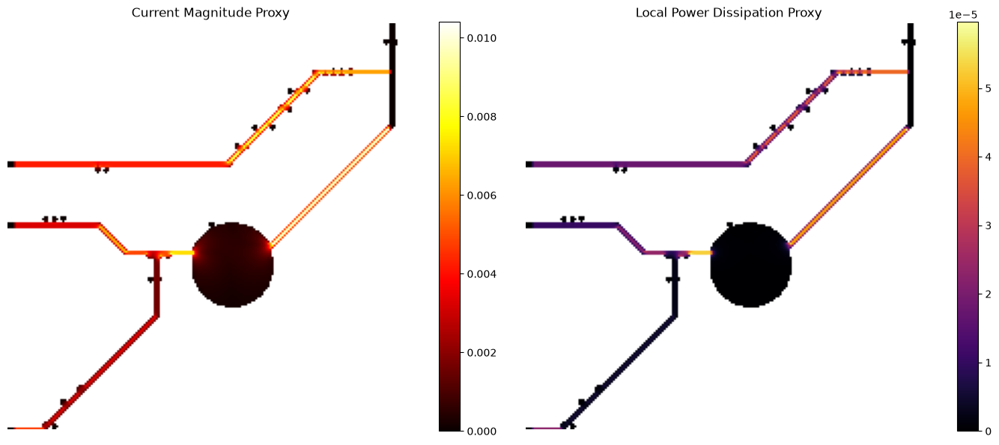

In [36]:
current_map = np.zeros((H, W), dtype=float)
power_map = np.zeros((H, W), dtype=float)

for dy, dx in [(1, 0), (0, 1)]:

    y0, x0 = np.where(roi_conductor)

    y1n = y0 + dy
    x1n = x0 + dx

    valid = (y1n < H) & (x1n < W)

    y0v = y0[valid]
    x0v = x0[valid]
    y1v = y1n[valid]
    x1v = x1n[valid]

    connected = roi_conductor[y1v, x1v]

    y0v = y0v[connected]
    x0v = x0v[connected]
    y1v = y1v[connected]
    x1v = x1v[connected]

    dV = (
        voltage_map[y0v, x0v] -
        voltage_map[y1v, x1v]
    )

    edge_current = np.abs(dV)
    edge_power = dV**2

    np.add.at(
        current_map,
        (y0v, x0v),
        edge_current / 2
    )
    np.add.at(
        current_map,
        (y1v, x1v),
        edge_current / 2
    )

    np.add.at(
        power_map,
        (y0v, x0v),
        edge_power / 2
    )
    np.add.at(
        power_map,
        (y1v, x1v),
        edge_power / 2
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(
    np.where(roi_conductor, current_map, np.nan),
    cmap="hot"
)
axes[0].set_title("Current Magnitude Proxy")
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(
    np.where(roi_conductor, power_map, np.nan),
    cmap="inferno"
)
axes[1].set_title("Local Power Dissipation Proxy")
plt.colorbar(im2, ax=axes[1])

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [37]:
records = []

for row in df_neck_path.itertuples(index=False):

    x = int(row.x_pixel) - x1
    y = int(row.y_pixel) - y1

    if not (0 <= x < W and 0 <= y < H):
        continue

    if not roi_conductor[y, x]:
        continue

    records.append({
        "path_id": row.path_id,
        "x_pixel": row.x_pixel,
        "y_pixel": row.y_pixel,
        "neck_score": row.neck_score,
        "voltage": voltage_map[y, x],
        "current_proxy": current_map[y, x],
        "power_proxy": power_map[y, x]
    })

df_electrical = pd.DataFrame(records)

if not df_electrical.empty:
    df_electrical = df_electrical.sort_values(
        "power_proxy",
        ascending=False
    ).reset_index(drop=True)

    df_electrical.insert(
        0, "rank",
        np.arange(1, len(df_electrical) + 1)
    )

display(df_electrical.head(20))

df_electrical.to_csv(
    OUTPUT_DIR / "electrical_candidate_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

,rank,path_id,x_pixel,y_pixel,neck_score,voltage,current_proxy,power_proxy
0,1,3462,689,1399,0.705039,0.555862,0.010151,5.371699e-05
1,2,3938,649,1403,0.781978,0.610256,0.007248,5.212332e-05
2,3,3867,627,1403,0.359504,0.730638,0.004592,1.807391e-05
3,4,3838,659,1391,0.815974,0.587300,0.000227,4.126137e-08
